## Abstract

In this computational study, a helix penalty shifts ESMFold2 binder designs toward β-rich structures across five targets, with lower predicted confidence. Helicity diverges early in optimization while the amino-acid distributions remain nearly uniform. Loss steering increases the number of candidates meeting the combined sheet and confidence criteria. In matched PD-L1 trajectories, changing the initial amino-acid probabilities also redirects early composition without a helicity penalty. Whether this initialization effect persists through full optimization and retains confidence remains to be tested.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
AI assistance was used to review the analysis and revise this draft. The author-approved disclosure will be added before publication.
:::

## Purpose

We wanted to make ESMFold2 produce more β-rich binder candidates without retraining the model. Its unmodified design procedure returned mostly helical structures in our campaigns, which limited the secondary-structure compositions available for screening.

We added a penalty for helix-like geometry and measured its effects across five targets. Tracking helicity alongside sequence entropy showed that the predictions diverge while the amino-acid distributions remain nearly uniform. This motivated a test of whether changing the starting amino-acid probabilities can redirect sequence optimization under the original objective. This notebook reports the effects of loss steering and a matched test of initialization during the first 40 sequence updates.

## Introduction

ESMFold2 is a structure prediction model that uses representations from the ESMC protein language model to predict proteins and their complexes. Alongside the model, @candido2026language present a binder-design algorithm that combines structural feedback from ESMFold2 with sequence feedback from ESMC. Starting from a soft sequence---a probability distribution over amino acids at each position---the algorithm repeatedly predicts the binder–target complex, evaluates a design objective, and updates the candidate sequence. As optimization proceeds, the soft sequence is progressively hardened into a discrete amino-acid sequence. The weights of both ESMC and ESMFold2 remain frozen, allowing researchers to design proteins under different objectives without retraining or fine-tuning either model. This approach builds on earlier work in protein hallucination and gradient-based sequence optimization [@anishchenko2021hallucination; @norn2021landscape; @frank2024relaxed], and was popularized for binder design by BindCraft [@pacesa2025bindcraft].

Although training data, model architectures, design objectives, and filtering choices differ among methods, a tendency toward α-helical designs has been reported in distinct binder-design workflows. BindCraft reports this tendency in its confidence-driven designs [@pacesa2025bindcraft], and RFdiffusion's developers note that the default model often generates predominantly helical binders [@rosettacommons2025rfdiffusiondocs]. A separate ten-target benchmark reports high helix content among RFdiffusion designs passing its computational screen, while PXDesign-d produces a broader range of helix fractions [@protenix2025pxdesign]. We observed a similar enrichment in unsteered ESMFold2 designs, motivating us to investigate how this preference could be changed.

Reducing this preference has several potential benefits: bringing designed secondary-structure compositions closer to those of natural binding proteins, increasing structural diversity within a campaign, and reaching binding sites that favor different interface geometries. The last motivation has experimental support. Guiding RFdiffusion toward β-strand pairing produced binders to exposed sheet edges, including on ALK-3 and KIT, where earlier design campaigns had failed [@sappington2026betapairing]. Such results motivate exploring alternatives to predominantly helical designs.

BindCraft already uses a helicity loss to obtain β-rich designs, with a decrease in computational screening success [@pacesa2025bindcraft]. To our knowledge, secondary-structure steering with a helicity penalty has not been demonstrated for ESMFold2. Understanding where the preference arises could also reveal other ways to intervene: a helical final design may reflect a preference already present in the initial prediction, its reinforcement during sequence optimization, or both.

Here, we investigate how to redirect ESMFold2's helix preference and what that costs in predicted confidence. We vary the strength of a helicity penalty across targets and track how the predictions change as the soft sequence becomes more concentrated. The penalty increases sheet content and the number of candidates passing a combined sheet-content and confidence screen, despite lowering average confidence. Helicity diverges early while sequence entropy remains near its maximum. This motivates testing whether changing the starting amino-acid probabilities can redirect optimization under the original objective.

:::{.callout-note collapse="true" title="GPU computation and reproducibility"}

Publication execution measures preserved model structures, scores and traces without running GPU models. The GPU outputs have not yet been publicly archived; reproduction currently requires those local inputs. Target inputs and the generation code are included in this repository.

New designs can be generated explicitly using `python -m analysis.campaign` after deploying the Modal workers. GPU runs cost compute and are not seed-reproducible, so new runs are new samples rather than replacements for the reported designs. See the reproduction guide for input locations and commands.

:::


In [2]:
# | include: false

import warnings

import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)

In [20]:
# | include: false
from analysis import (
    artifacts,
    composition,
    deposit,
    figures,
    loss_trace,
    paths,
    reference,
    targets,
)

paths.ensure_dirs()
if any(not artifacts.status(t, a).is_analysable for t, a in targets.publication_campaigns()):
    deposit.DESIGN_TABLES.fetch()

## Unsteered designs are helix-rich relative to natural proteins

We generated 30 unsteered binders per target using the five constructs from the ESMFold2 paper [@candido2026language] (@tbl-targets). Binder lengths were sampled from a 60–200-residue range.

| Target | Target region | UniProt ID | UniProt residues | Target length (aa) |
|---|---|---|---|---:|
| EGFR | Domain III | [P00533](https://www.uniprot.org/uniprotkb/P00533/entry) | 334–524 | 191 |
| PDGFRβ | Domains D2–D3 | [P09619](https://www.uniprot.org/uniprotkb/P09619/entry) | 126–312 | 187 |
| PD-L1 | IgV domain | [Q9NZQ7](https://www.uniprot.org/uniprotkb/Q9NZQ7/entry) | 18–132 | 115 |
| CTLA-4 | IgV domain | [P16410](https://www.uniprot.org/uniprotkb/P16410/entry) | 38–155 | 118 |
| CD45 | Domains d3–d4 | [P08575](https://www.uniprot.org/uniprotkb/P08575/entry) | 390–574 | 185 |

: Human target constructs from Table S10 of @candido2026language. Residue ranges use canonical UniProt numbering and include both endpoints. {#tbl-targets}

To compare their secondary-structure composition with binders found in nature, we queried the RCSB Protein Data Bank for experimentally resolved complexes containing two distinct protein entities and selected chains within the same 60–200-residue range. We refer to each selected chain as the natural binder and the other as its partner.

We then compared the helix, sheet, and loop fractions of the two groups within five binder-length bins (@fig-composition).

:::{.callout-note collapse="true" title="Natural protein baseline construction"}

We selected X-ray structures containing two distinct protein entities and a binder with a named source organism other than "synthetic construct," retaining one representative per sequence-identity cluster. We excluded records annotated as designed proteins and chains outside the length range or with insufficient resolved backbone. The code below recalculates measurements from archived RCSB inputs and applies these selection criteria. Small interfaces and peptide partners are flagged but retained.

Both natural and designed chains are measured with PyDSSP using the same backbone-based helix, sheet, and loop assignments [@minami2024pydssp]. Only residues with N, Cα, C, and O coordinates contribute to the fractions.

In [9]:
# | code-fold: true
# | code-summary: "Measure and select the natural protein reference"

reference_pairs = reference.pairs()
eligible = (
    reference_pairs["cluster_representative"].eq(1)
    & reference_pairs["measured"].eq(1)
    & reference_pairs["binder_design_like"].eq(0)
    & reference_pairs["excluded_short_or_long"].eq(0)
    & reference_pairs["excluded_incomplete"].eq(0)
)
natural = reference_pairs.loc[eligible].reset_index(drop=True)

for setting, value in reference.recorded_query_settings().items():
    print(f"{setting}: {value}")
print(f"Retained reference: {len(natural):,} chains from {natural.pdb_id.nunique():,} PDB entries")
print(f"  Small-interface flag: {int(natural.flag_small_interface.sum()):,} chains")
print(f"  Peptide-partner flag: {int(natural.flag_peptide_target.sum()):,} chains")

using the recorded search results in natural_binder_search_hits.json, snapshot 2026-09-02
downloading 2385 mmCIF files...
  downloaded 200/2385
  downloaded 400/2385
  downloaded 600/2385
  downloaded 800/2385
  downloaded 1000/2385
  downloaded 1200/2385
  downloaded 1400/2385
  downloaded 1600/2385
  downloaded 1800/2385
  downloaded 2000/2385
  downloaded 2200/2385
measuring 2385 entries...
  measured 200 entries (20 failures)
  measured 400 entries (35 failures)
  measured 600 entries (51 failures)
  measured 800 entries (61 failures)
  measured 1000 entries (87 failures)
  measured 1200 entries (104 failures)
  measured 1400 entries (128 failures)
  measured 1600 entries (146 failures)
  measured 1800 entries (160 failures)
  measured 2000 entries (173 failures)
  measured 2200 entries (189 failures)
{
  "snapshot_release_date": "2026-09-02",
  "in_range_entities": 10601,
  "in_range_entries": 8319,
  "clusters": 2790,
  "cluster_representatives": 2790,
  "measured": 2592,
  "excl

:::

In [4]:
# | code-fold: true
# | code-summary: "Measure unsteered binder composition for each target"

TARGETS = list(targets.TARGET_SPECS)
campaign_composition = {}
for target in TARGETS:
    campaign_composition[target, "vanilla"] = composition.measure_campaign(target, "vanilla")

designs = pd.concat(campaign_composition.values(), ignore_index=True)

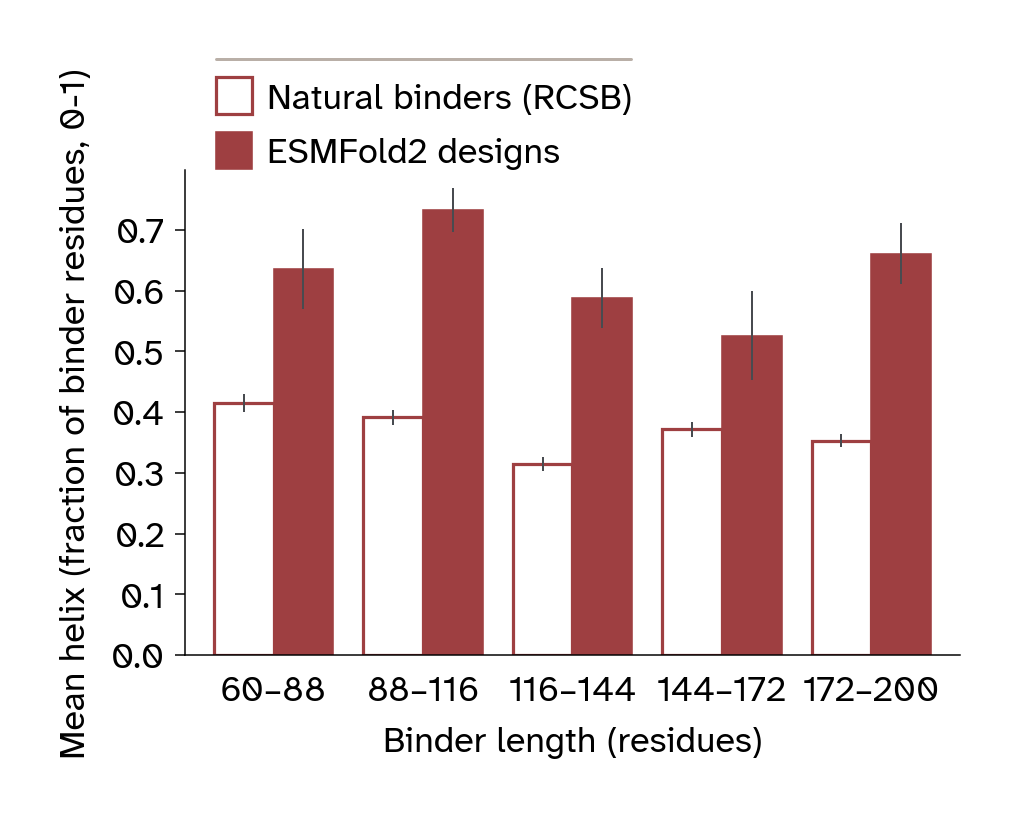

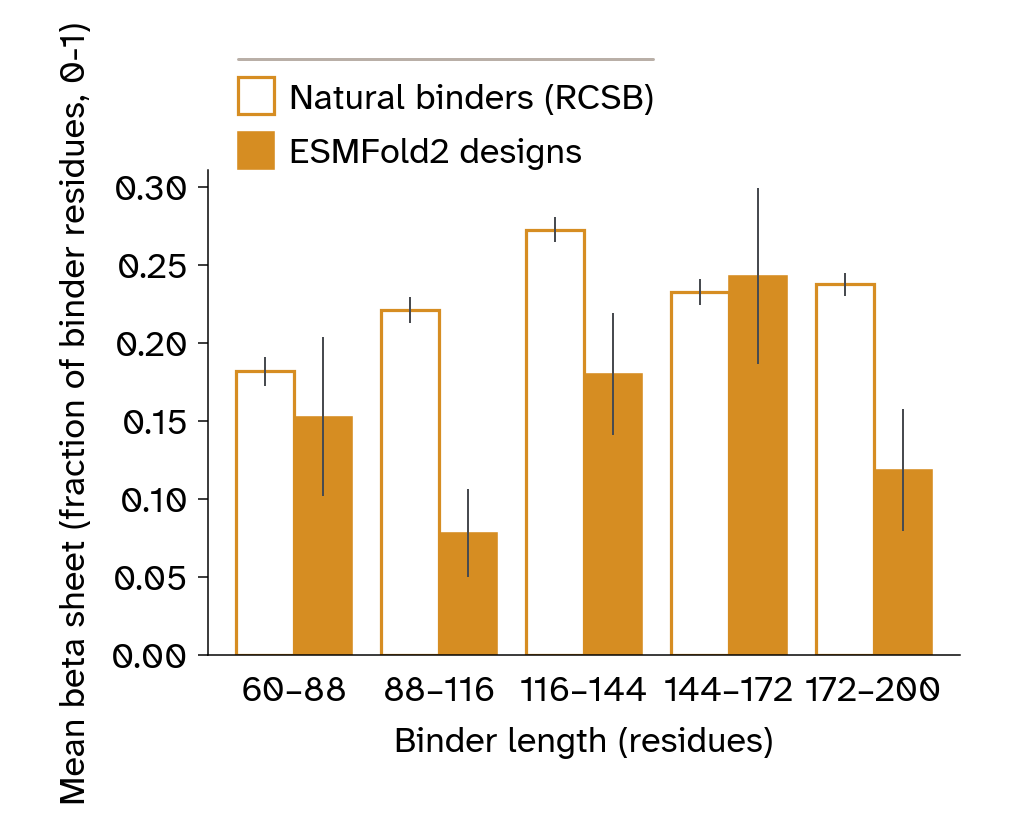

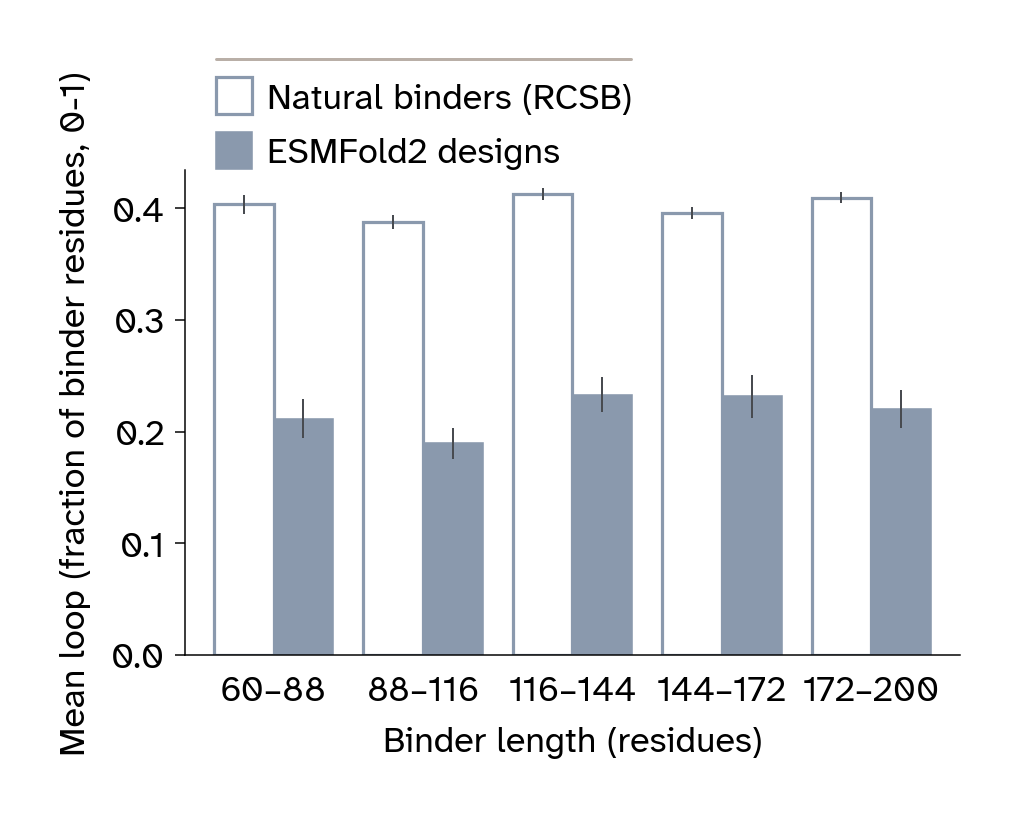

In [5]:
# | label: fig-composition
# | fig-cap: "Secondary-structure composition of unsteered designs and the experimental reference, grouped into five binder-length bins. Unfilled bars show the reference and filled bars show designs. Each chain contributes once to its bin. Bars are means; whiskers are standard errors across chains. Panel y-axes differ."
# | fig-subcap:
# |   - "Helix"
# |   - "Beta sheet"
# |   - "Loop"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Compare chain means and standard errors within five length bins"

import numpy as np
from matplotlib import pyplot as plt

length_edges = np.linspace(60, 200, 6)
length_summaries = {}
for state, columns in figures.STATES.items():
    reference_summary = composition.summarize_by_length(
        natural[columns.natural_column], natural["binder_sample_length_residues"], length_edges
    )
    design_summary = composition.summarize_by_length(
        designs[columns.design_column], designs["binder length (residues)"], length_edges
    )
    length_summaries[state] = {"natural": reference_summary, "designs": design_summary}
    figures.composition_comparison(reference_summary, design_summary, state, length_edges)

Unsteered ESMFold2 designs are substantially more helical than the natural reference, with correspondingly less sheet and loop (@fig-composition). This pattern recurs across binder lengths and all five targets, suggesting a persistent preference in the design workflow. Redirecting that preference could help a design campaign explore more of the secondary-structure compositions found among natural binding partners.

## A helix penalty changes the design objective

The reference comparison suggests a practical opportunity: reduce the predominance of helices so that a campaign samples more of the sheet-containing compositions found in natural complexes. To test this, we added a term to the existing objective that penalizes helix-like geometry.

### The existing structural objective

The default structural loss combines intrabinder contacts, contacts between the target and binder, and a size-dependent compactness term:

$$
\mathcal{L}_{\mathrm{struct}}
= 0.5\,\mathcal{L}_{\mathrm{intra}}
+ 0.5\,\mathcal{L}_{\mathrm{inter}}
+ 0.2\,\mathcal{L}_{\mathrm{glob}}.
$$

The intrabinder term favors nonlocal contacts within the binder. The interface term asks each target residue for a contact with the binder, and the compactness term favors smaller predicted binder dimensions. For details, see @candido2026language.

### Penalizing helix-like distances

We use a local geometric feature of an α helix: residues four positions apart have nearby Cα atoms. For each eligible binder position, we sum the distogram probability below 7 Å and average over positions:

$$
\mathcal{L}_{\mathrm{helix}}=\frac{1}{L-4}\sum_{i=1}^{L-4}
P(d_{i,i+4}<7\ \text{Å})\in[0,1].
$$

The final four residues have no partner at this offset and are excluded from the average. The penalty acts only on the binder block of the distogram.

To steer sequence optimization, we replace the default structural objective $\mathcal{L}_{\mathrm{struct}}$ with an objective that includes the weighted helicity penalty:

$$
\mathcal{L}^{\prime}_{\mathrm{struct}}
=\mathcal{L}_{\mathrm{struct}}+w\,\mathcal{L}_{\mathrm{helix}}.
$$

Increasing the weight $w$ makes these short $i,i+4$ distances more costly.

The term $\mathcal{L}_{\mathrm{helix}}$ is a differentiable proxy, not a secondary-structure assignment. A low value does not distinguish a beta strand from an irregular extended segment, and it does not specify how strands should pair. We therefore evaluate the resulting structures separately with PyDSSP. @fig-scene illustrates the distance criterion on an example protein.

:::{.callout-note collapse="true" title="Relationship to BindCraft's helicity loss"}

We developed this formulation before becoming aware of BindCraft's helicity loss [@pacesa2025bindcraft]. Both use the same underlying strategy of steering secondary structure by discouraging short intrabinder distances characteristic of helices. BindCraft's [implementation](https://github.com/martinpacesa/BindCraft/blob/7cd4ace1b7407adf66a50dfefa47de2270f5e4a9/functions/colabdesign_utils.py) averages a [negative-log contact probability](https://github.com/sokrypton/ColabDesign/blob/24a449493c9e60fc8fefd4981a4b83f7900b9110/colabdesign/af/loss.py) for binder residue pairs separated by three positions, using a 6Å cutoff. Our formulation averages contact probabilities for pairs separated by four positions, using a 7Å cutoff. We have not made a direct comparison of the two formulations under matched conditions.
:::

In [6]:
# | label: fig-scene
# | fig-cap: "A predicted binder colored by the coordinate-based distance criterion underlying the penalty. Red marks an i-to-i+4 Cα pair below 7 Å; each such pair contributes 1/(L-4) to the binary coordinate average. The last four residues are unscored. Hovering shows the measured pair and distance. Keep in mind that the optimized loss uses distogram probabilities rather than realized coordinate values."
# | code-fold: true
# | code-summary: "Inspect the i-to-i+4 distance criterion on an example binder"

from analysis import scene

scene.loss_term_scene(paths.ASSETS / "example-complex.pdb").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Increasing the weight replaces helix with sheet and loop

We compared weights of 0, 0.5, 1.0, 2.0, and 5.0, with 30 seeds per condition on each target. @fig-scan-1 shows the mean composition pooled across all five targets; @fig-scan-2 shows the pooled distribution of helix fractions.

In [7]:
# | code-fold: true
# | code-summary: "Measure the target-by-weight comparison, with 30 designs per condition"

ARMS = list(targets.CAMPAIGN_ARMS)
for target in TARGETS:
    for arm in ARMS:
        if (target, arm) not in campaign_composition:
            campaign_composition[target, arm] = composition.measure_campaign(target, arm)

steered = pd.concat(campaign_composition.values(), ignore_index=True)
campaign_sizes = steered.groupby(["target", "arm"]).size()
assert campaign_sizes.eq(targets.N_SEEDS).all()

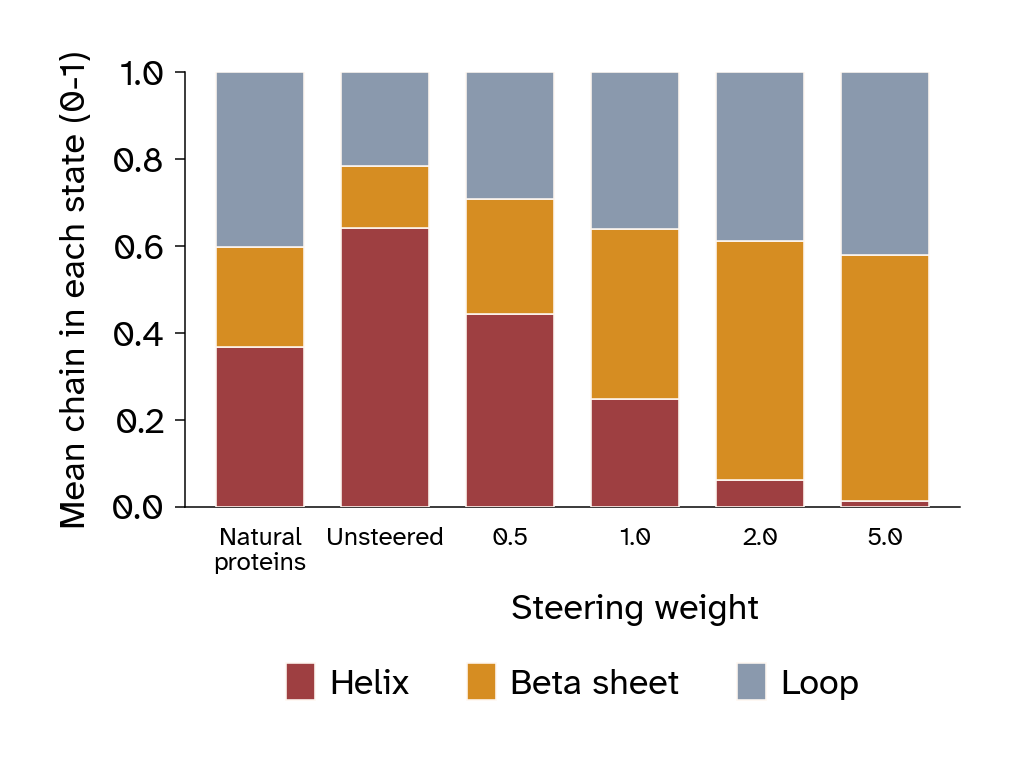

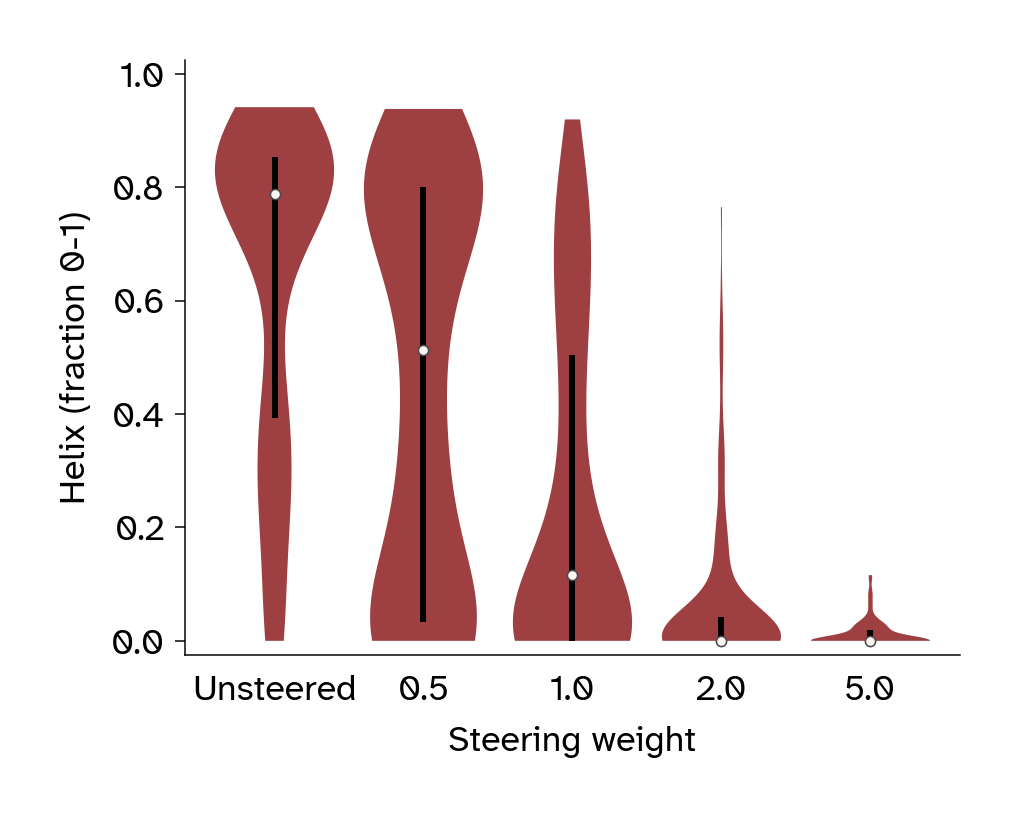

In [8]:
# | label: fig-scan
# | fig-cap: "Secondary-structure composition across steering weights. The stacked bars pool all five targets, with 150 designs per weight and equal contributions from each target; the reference includes all natural chains without resampling or weighting. The violins show smoothed helix-fraction distributions for the same 150 designs per weight, restricted to each group’s observed range and scaled to equal maximum width. White dots mark medians; thick vertical lines span the interquartile range. PyDSSP assigns secondary structure from backbone coordinates: the primary critic’s final predicted complexes for designs and experimental structures for the natural reference."
# | fig-subcap:
# |   - "Mean PyDSSP helix, sheet, and loop fractions from final predicted binder structures across all five targets (150 designs per weight). The natural reference uses PyDSSP assignments from experimental structures."
# |   - "Distribution of PyDSSP helix fractions from final predicted binder structures across all five targets (150 designs per weight). Dots mark medians; lines span the interquartile range."
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Pool chain composition by steering weight and inspect helix distributions"

composition_means = {}
for state, columns in figures.STATES.items():
    design_means = steered.groupby("arm")[columns.design_column].mean().reindex(ARMS)
    composition_means[state] = pd.concat(
        [pd.Series({"natural": natural[columns.natural_column].mean()}), design_means]
    )
composition_means = pd.DataFrame(composition_means)

figures.composition_means(composition_means)
figures.scan_violin(steered, ARMS, "helix")
plt.show()

@fig-scan-1 shows that penalizing helix-like distances increases both sheet and loop content. At the strongest weights, helices are almost absent, while sheets account for just over half of the mean composition.

The pooled distributions in @fig-scan-2 reveal heterogeneous responses to intermediate steering weights. In particular, at $w=0.5$, the helix-fraction distribution appears bimodal, with some designs remaining strongly helical, while others contain little helix. This pattern suggests that modest steering can substantially redirect some optimization trajectories while leaving others helix-rich. Both helix-rich and helix-poor designs also occur within individual targets (@fig-generality).

### The response occurs on all five targets

We next examined how individual targets contribute to the pooled response. @fig-generality shows the distributions of helix, sheet, and loop fractions for every target and weight.

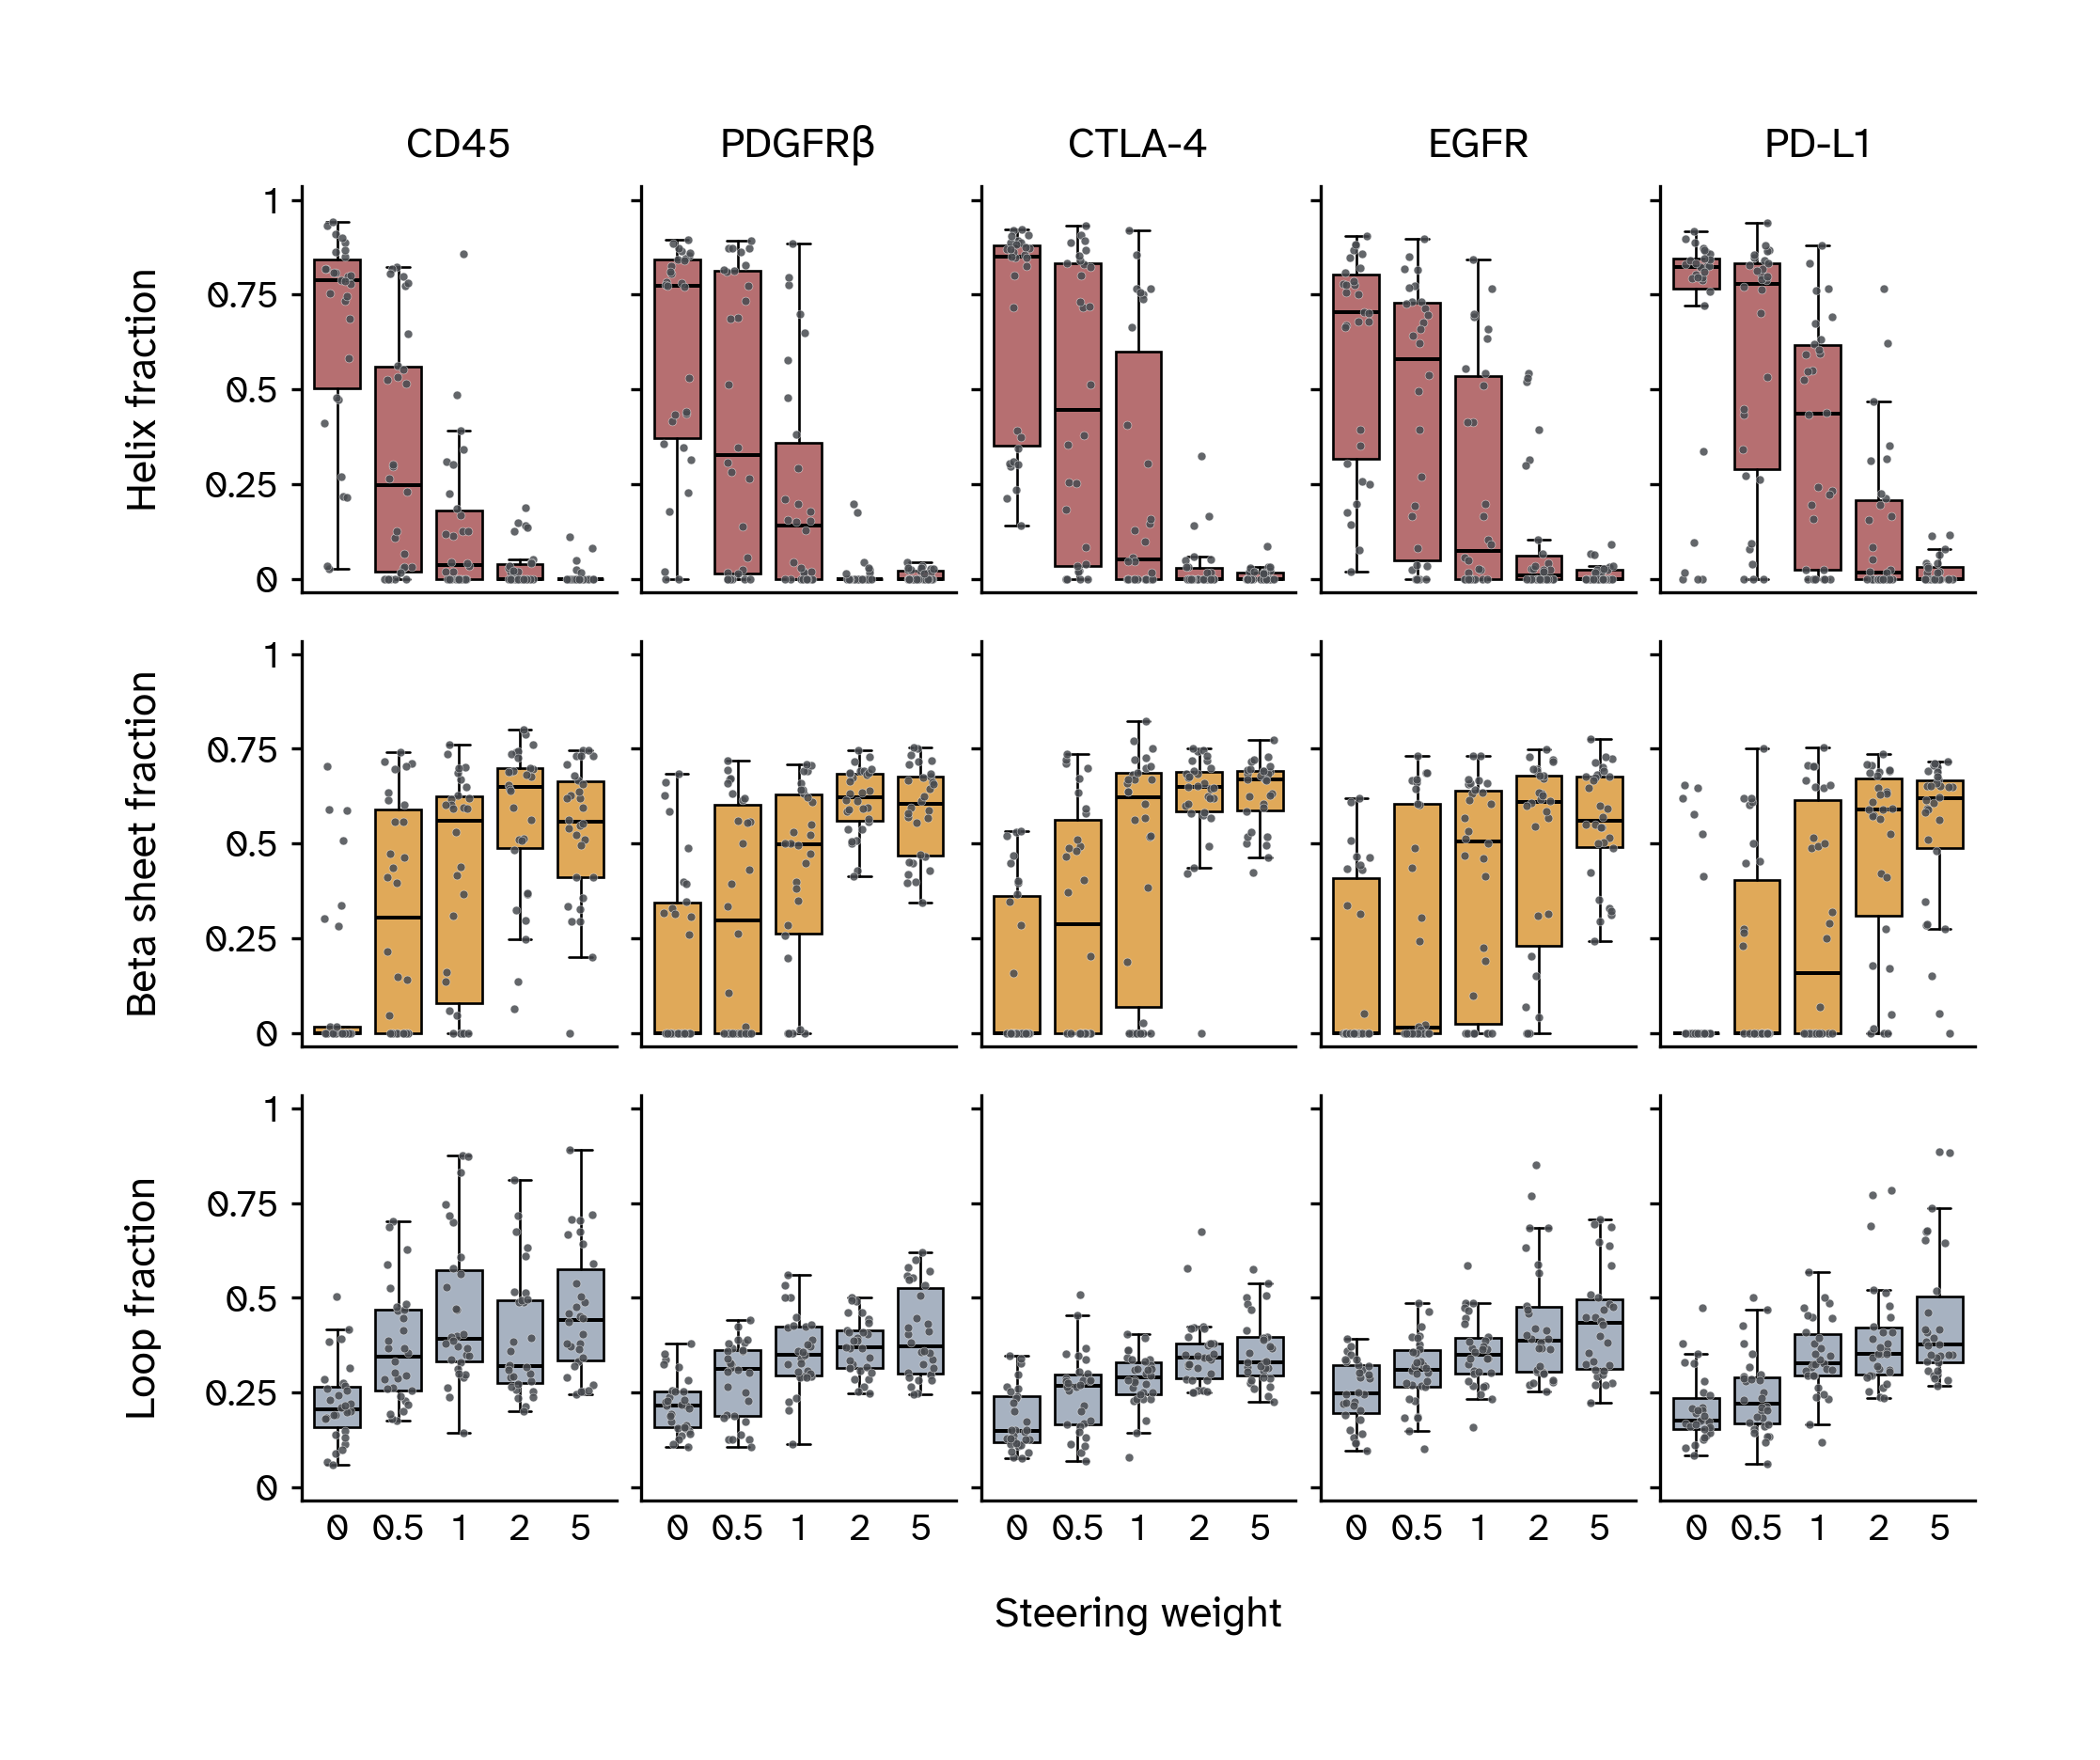

In [9]:
# | label: fig-generality
# | fig-cap: "Final secondary-structure fractions across all five targets and steering weights (30 designs per target and weight), assigned by PyDSSP from the primary critic’s predicted binder structures. Rows show helix, sheet, and loop fractions; columns show targets, with shared axes. Points show individual designs with horizontal jitter; boxes span the interquartile range, central lines mark medians, and whiskers extend to the most extreme observations within 1.5 times the interquartile range. Zero denotes unsteered design. Conditions are equally spaced; spacing does not represent the numerical difference between weights."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare compositions by target, ordered by median helicity at weight 0.5"

TARGET_ORDER = (
    steered[steered["arm"] == "helix_mean_w05"]
    .groupby("target")["helix (fraction 0-1)"]
    .median()
    .sort_values()
    .index.tolist()
)
figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("helix", "sheet", "loop"))
plt.show()

Median helix decreases with weight on all five targets, with some targets being more responsive to intermediate weights (e.g. CD45) than others (e.g. PD-L1). Yet all reach a median helix fraction of zero by weight 5.0. Commensurately, beta sheet and loop proportions increase, indicating a shift toward sheet-rich designs with substantial loop content. The broad distributions at intermediate weights show that a given steering weight can still yield very different compositions that depends on the initial seed.

### Steering lowers confidence

Steering produces more sheet-rich designs, but does it retain enough high-confidence candidates to make that change useful for a design campaign? We assessed confidence in the binder–target arrangement using *interface predicted TM-score* (ipTM), and confidence in local binder structure using binder *predicted local distance difference test score* (pLDDT). @fig-cost and @tbl-cost show how confidence changes across the full population of designs.

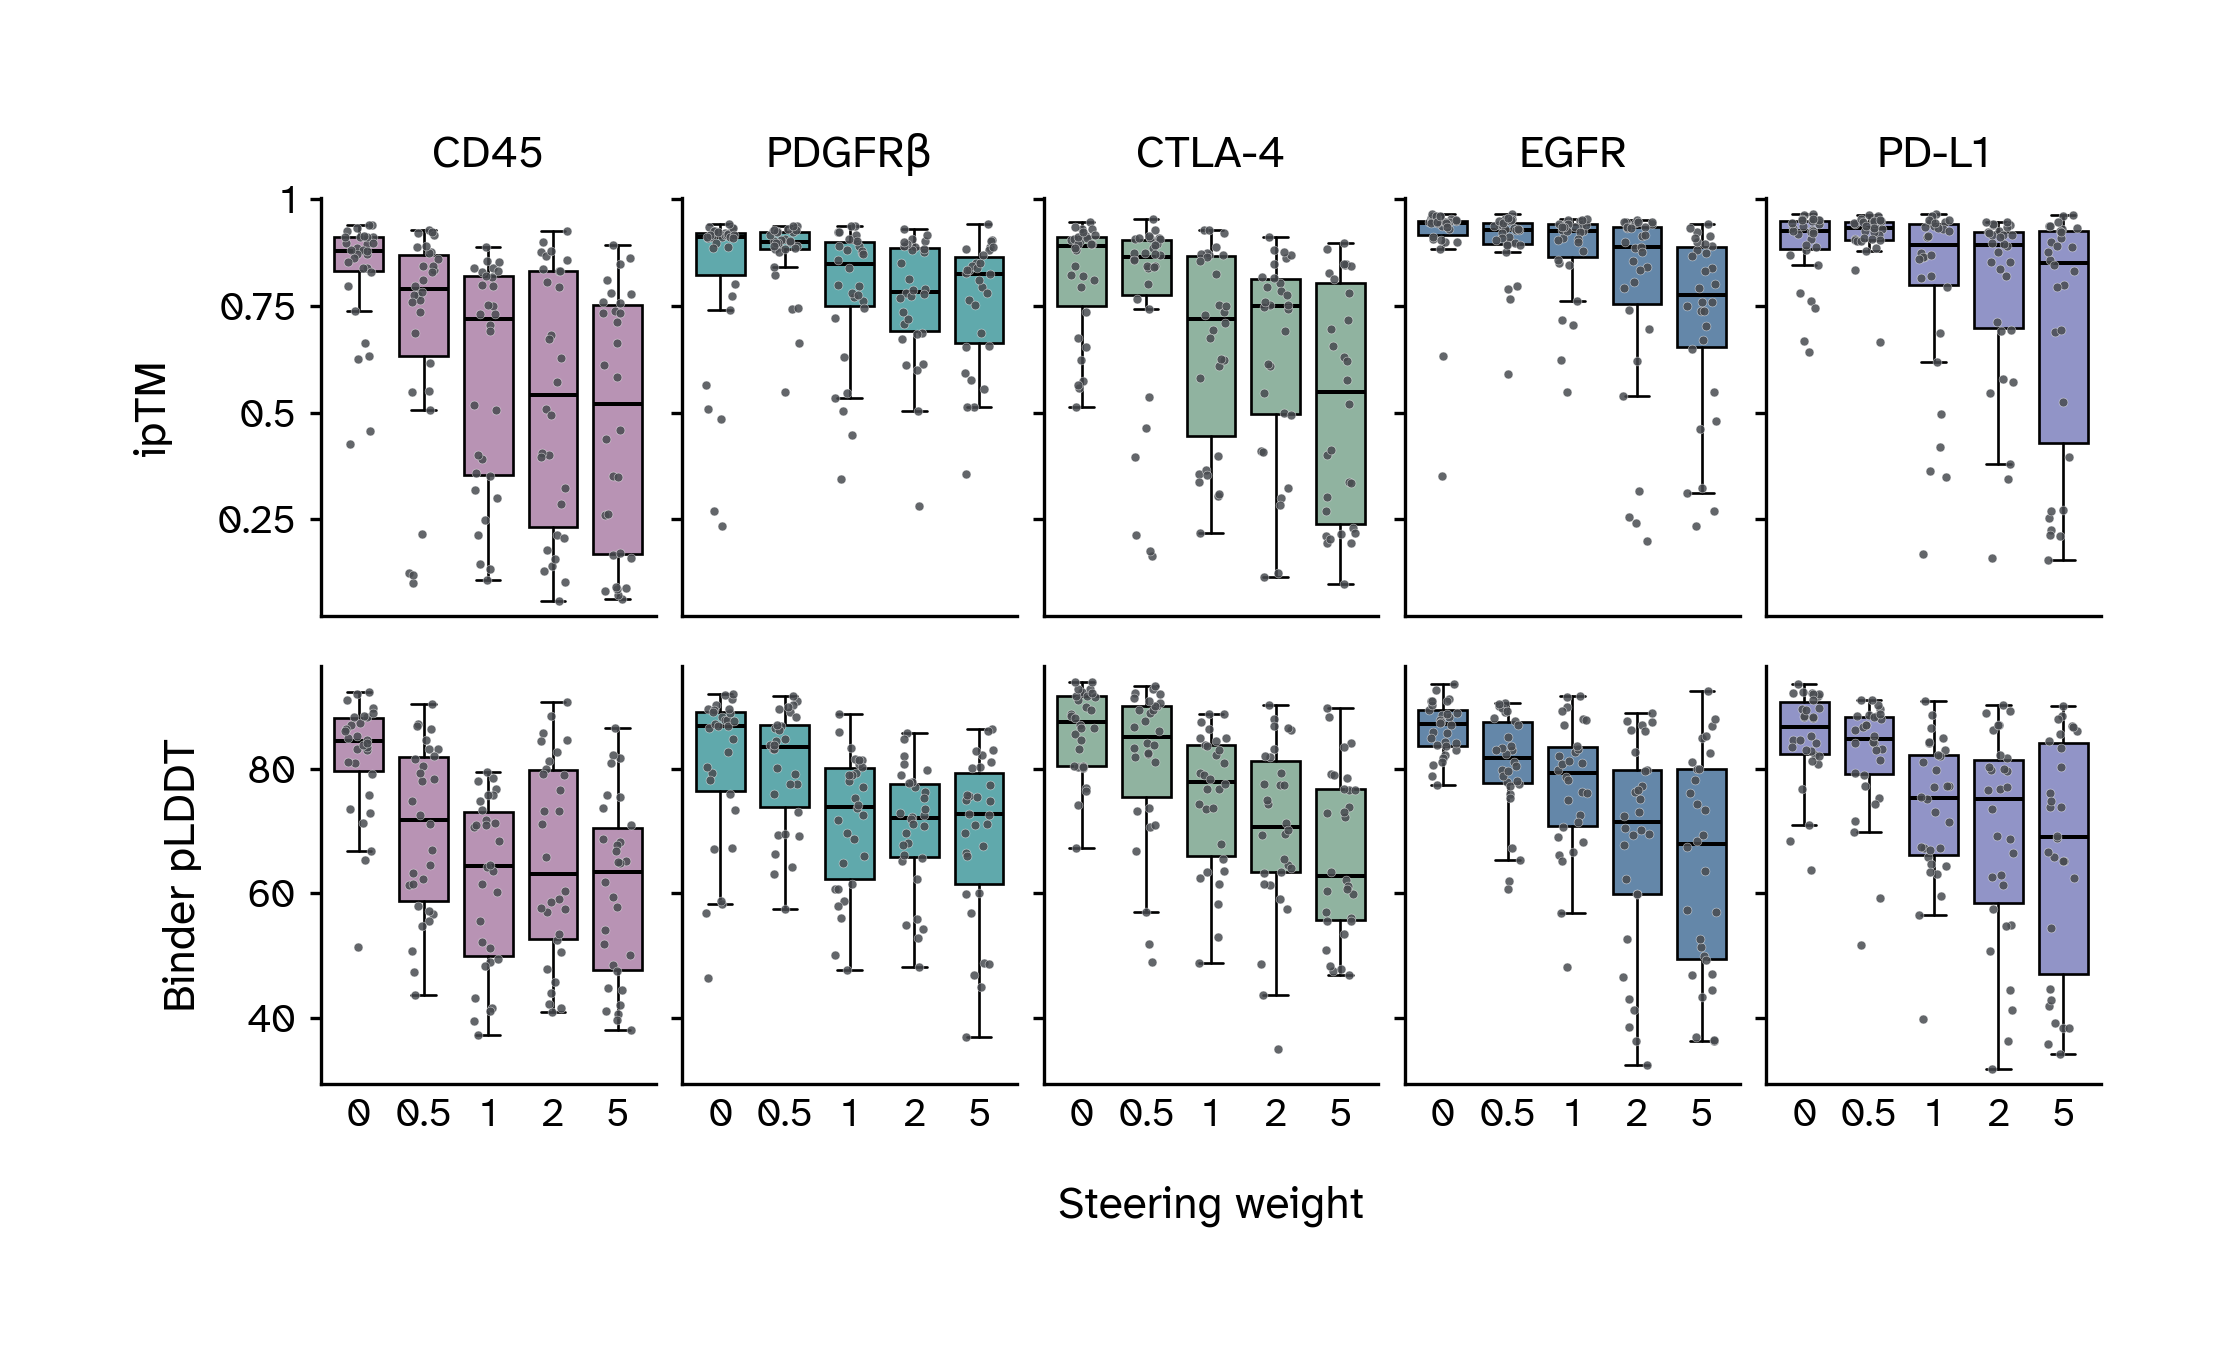

In [10]:
# | label: fig-cost
# | fig-cap: "Primary-critic ipTM (top) and binder pLDDT (bottom) across steering weights, with 30 designs per target and weight. Columns use the same target order as @fig-generality. Points show individual designs with horizontal jitter; boxes span the interquartile range, central lines mark medians, and whiskers extend to the most extreme observations within 1.5 times the interquartile range. Box colors identify targets. Y-axis limits are shared within each row and span the observed values; neither row starts at zero. Zero on the x-axis denotes unsteered design. Conditions are equally spaced; spacing does not represent the numerical difference between weights."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare final confidence distributions by target and steering weight"

figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("iptm", "plddt"))
plt.show()

In [11]:
# | label: tbl-cost
# | tbl-cap: "Median primary-critic ipTM and binder pLDDT by target and steering weight, each based on 30 designs. ipTM is on a 0–1 scale; binder pLDDT is on a 0–100 scale."
# | code-fold: true
# | code-summary: "Calculate median confidence by target and steering weight"

from analysis import tables
from IPython.display import display

cost_metric_labels = {
    "iptm (0-1)": "ipTM",
    "binder pLDDT (0-100)": "Binder pLDDT",
}
cost_tables = {}
for column, label in cost_metric_labels.items():
    cost_tables[label] = (
        steered.groupby(["target", "arm"])[column]
        .median()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )

cost_table = pd.concat(cost_tables, names=["Metric", "Target"])
display(tables.confidence(cost_table))

Both confidence measures generally decline as steering increases, although the size of the decline depends on the target. EGFR and PD-L1 retain relatively high interface confidence, while CD45 shows a more pronounced reduction. Even at strong steering weights, some candidates retain high confidence scores. We therefore counted how many designs pass the confidence screen and how many also meet the sheet-content requirement.

To distinguish these outcomes, we apply two *in silico* screens (@tbl-screen-criteria). The quality screen uses pLDDT and ipTM thresholds. The combined screen additionally requires a predicted sheet fraction above 0.40. The thresholds for both screens are shown below.

| Screen | Requirements |
|---|---|
| Quality | ipTM > 0.85 and pLDDT > 80 |
| Quality + sheet content | Quality criteria and sheet fraction > 0.40 |

: Criteria defining a candidate that passes each in silico screen. {#tbl-screen-criteria}

@tbl-sheet-screen reports the number of candidates passing each screen, so the loss of high-confidence candidates can be compared directly with the yield of candidates that also have the desired composition.

In [12]:
# | label: tbl-sheet-screen
# | tbl-cap: "Candidates passing each in silico screen by target and steering weight. Each target has 30 designs per weight, for 150 designs per column. Pass rates use all designs at that weight as the denominator. Confidence scores and PyDSSP secondary structure come from the primary critic."
# | code-fold: true
# | code-summary: "Count candidates passing each screen"

quality_pass = (steered["iptm (0-1)"] > composition.MIN_IPTM) & (
    steered["binder pLDDT (0-100)"] > composition.MIN_BINDER_PLDDT
)
screens = {
    "Quality": quality_pass,
    "Quality + sheet content": quality_pass
    & (steered["sheet (fraction 0-1)"] > composition.MIN_SHEET_FRACTION),
}
screen_denominators = steered.groupby("arm").size().reindex(ARMS)
screen_tables = {}
for screen, passed in screens.items():
    counts = (
        steered.assign(passed=passed)
        .groupby(["target", "arm"])["passed"]
        .sum()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )
    counts.loc["Total"] = counts.sum()
    counts.loc["Pass rate"] = counts.loc["Total"] / screen_denominators
    screen_tables[screen] = counts

screen_table = pd.concat(screen_tables, names=["Screen", "Target"])
display(tables.screen_counts(screen_table))

Steering reduces the pooled number of candidates passing the quality screen, yet every tested steering weight yields more candidates passing the combined screen than unsteered design. At weight 2.0, quality passes fall from 103 to 30, while quality + sheet content passes rise from 15 to 29. Nearly all candidates that retain high confidence at this weight also meet the sheet requirement. **Steering therefore trades a larger pool of high-confidence candidates for a smaller pool, but enriched in the desired composition**.

Overall, steering away from ESMFold2's helix preference comes at the cost of lower *in silico* confidence. However, the biological meaning of that reduction remains unresolved. It could be that ESMFold2 confidence scores are well-calibrated with biological reality and the generated beta-sheet designs yield lower average scores because they're less likely to fold and bind well. Though it could also be that they average lower scores simply because of ESMFold2's demonstrated bias towards alpha-helix (@fig-composition). Experimentally testing the designs could settle this.

## Helicity diverges while sequences remain soft

The final structures show how strongly steering changes composition, but not when those differences emerge during optimization. We tracked the helix proxy, interface-confidence proxy, and sequence entropy throughout optimization to see how the structural predictions develop as the soft sequence hardens (@fig-trace).

In [13]:
# | code-fold: true
# | code-summary: "Calculate per-step medians across designs for each steering weight"

campaign_traces = {}
for target in TARGETS:
    for arm in ARMS:
        campaign_traces[target, arm] = loss_trace.load_campaign(target, arm)
trace = pd.concat(campaign_traces.values(), ignore_index=True)

trace_columns = {
    "helix_mean": "helix_mean (0-1)",
    "iptm_proxy": "distogram iptm proxy (0-1)",
    "entropy": "sequence entropy (bits)",
}
trace_medians = (
    trace.groupby(["arm", "step (index)"])[list(trace_columns.values())].median().reset_index()
)

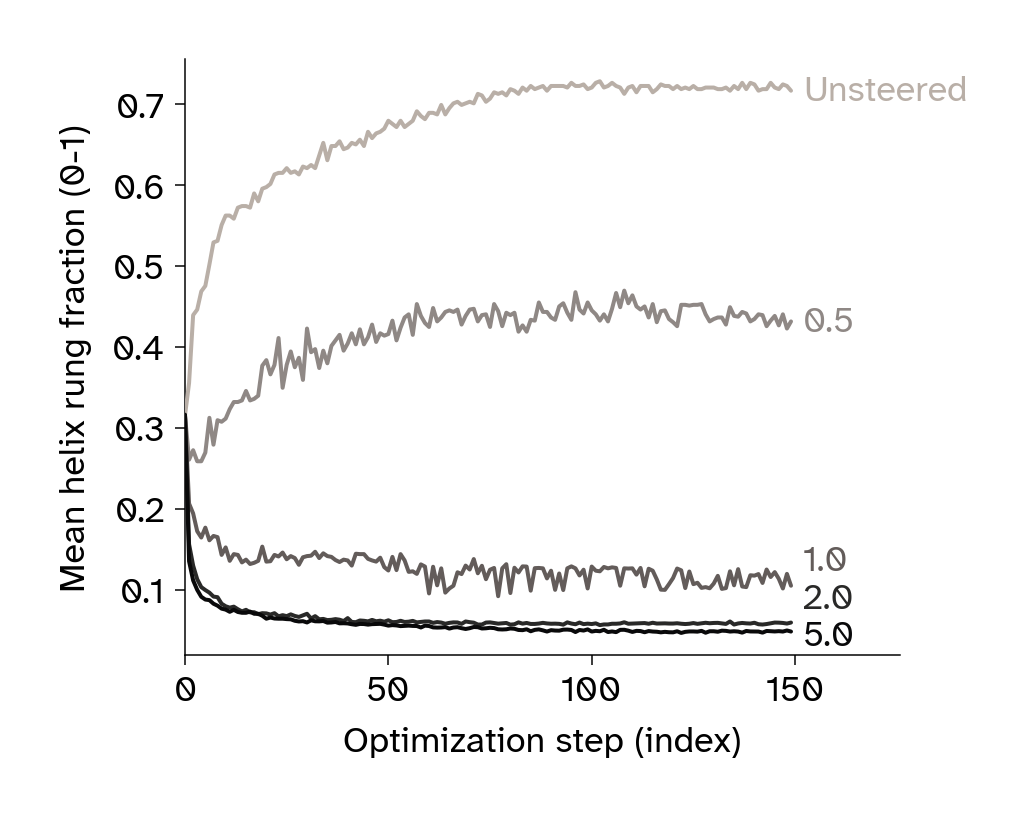

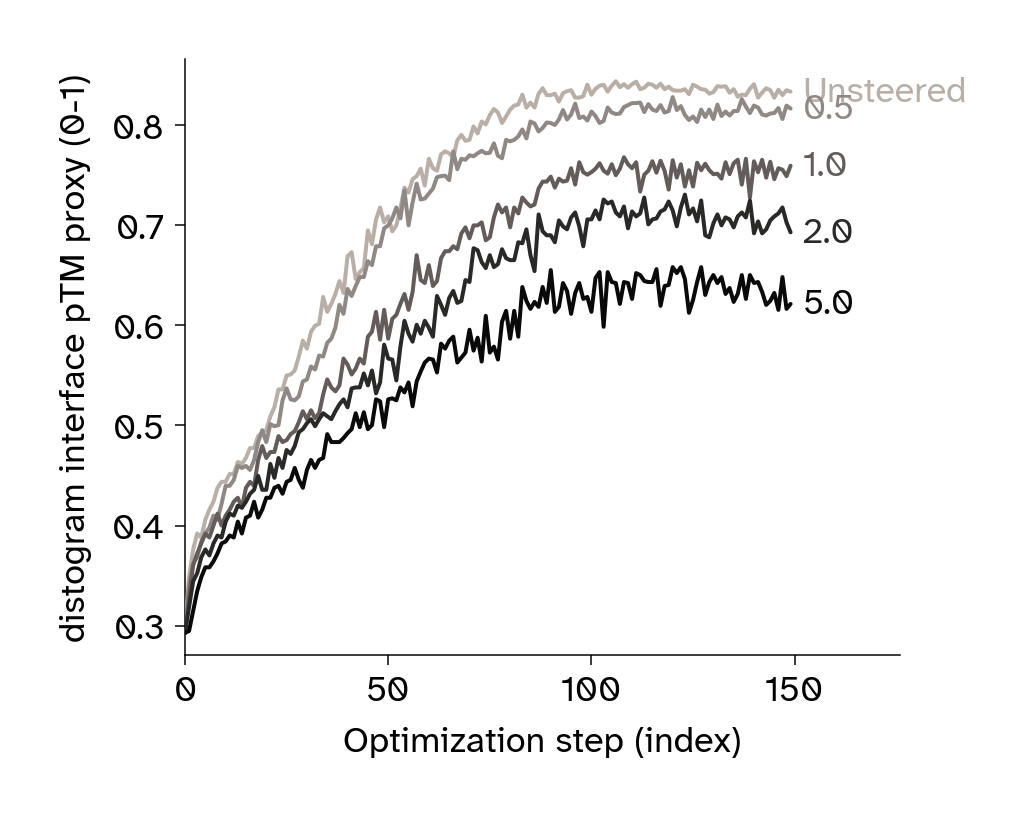

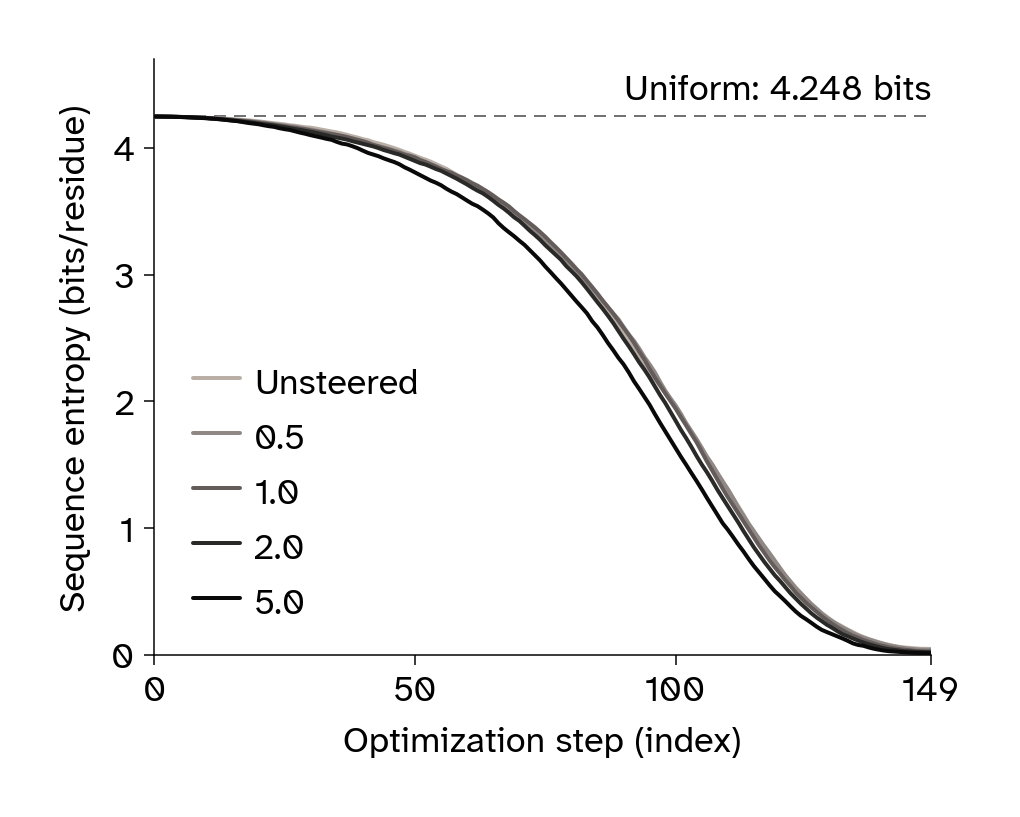

In [14]:
# | label: fig-trace
# | fig-cap: "Median optimization diagnostics across 150 designs per condition, pooling five targets. The helix proxy is the mean predicted short-distance probability; the interface proxy is also computed from the distogram. Neither is the final primary-critic readout. Sequence entropy is the mean per-residue entropy of the soft amino-acid probabilities; the dashed line marks the uniform maximum over the 19 allowed amino acids (cysteine is excluded)."
# | fig-subcap:
# |   - "The loss term's own value"
# |   - "Distogram interface pTM proxy"
# |   - "Sequence entropy"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Plot median helicity, interface proxy, and sequence entropy during optimization"

for metric in trace_columns:
    figures.trace_summary(trace_medians, metric, ARMS)

Interestingly, helicity separates within the first few optimization steps. Without steering, the helicity rises aggressively. With a moderate weight of 0.5, this rise is slower and plateaus earlier. And with stronger weights, the helicity drops below the initial value. By step 20, its pooled median ranges from 0.60 without steering to 0.06 at weight 5.0. Yet within this early stage of optimization, median sequence entropy holds between 4.19 and 4.21 bits per residue across all weight, barely droppping from the uniform maximum of 4.25. This illustrates that the predictions have developed markedly different helicity despite the amino-acid distributions perturbing only slightly from uniform.

:::{.callout-note collapse="true" title="Individual trajectories show the range of responses"}

It's worth keeping in mind that the median trajectories in @fig-trace summarize runs with sometimes vastly different outcomes, even under the same steering weight. To illustrate this, we show the thirty CD45 runs at weight 1.0 below, where it's clear that both low- and high-helicity endpoints are observerd (@fig-seeds).

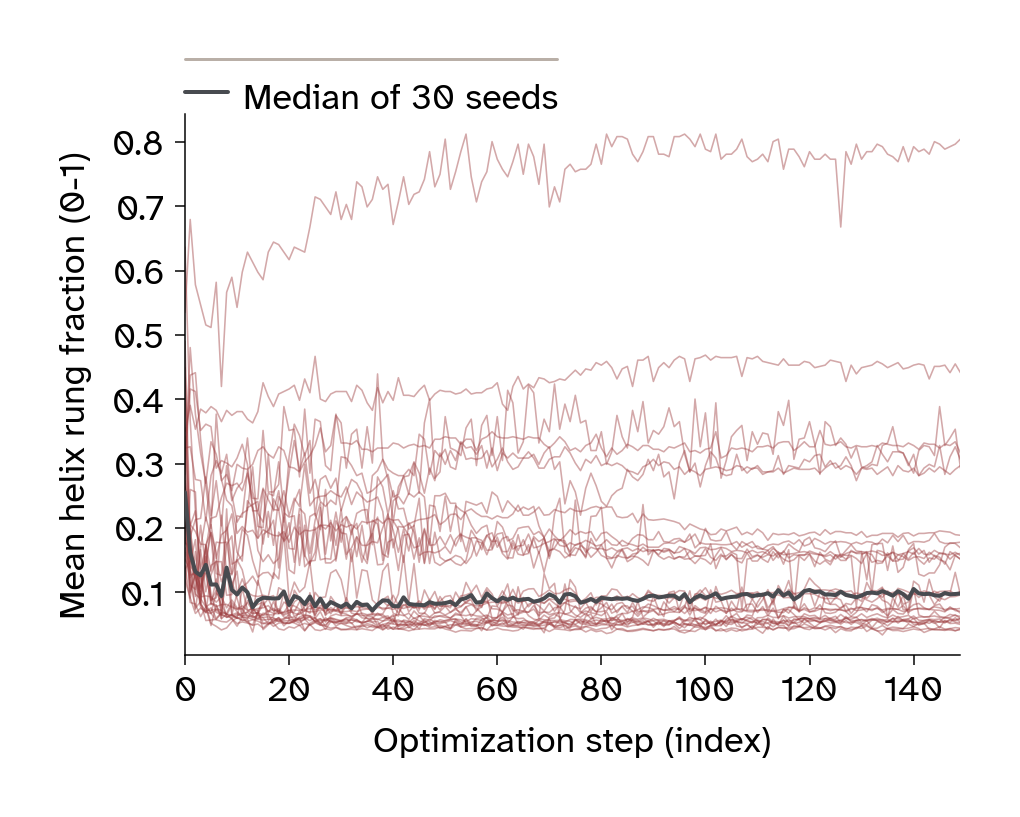

In [15]:
# | label: fig-seeds
# | fig-cap: "Distogram helicity trajectories for all thirty CD45 runs at weight 1.0. Thin lines show individual seeds and the thick line shows their median. These values are the optimization proxy, not final PyDSSP helix fractions."
# | code-fold: true
# | code-summary: "Inspect individual CD45 trajectories and their final helicity proxies"

selected_traces = trace[(trace["target"] == "cd45_d3d4") & (trace["arm"] == "helix_mean_w10")]
final_proxy = selected_traces.loc[
    selected_traces["step (index)"] == targets.SGD_STEPS - 1, "helix_mean (0-1)"
]
figures.seed_traces(selected_traces, "cd45_d3d4", "helix_mean_w10", "helix_mean");

:::

## Investigating sequence initialization {#sec-initialization}

In @fig-trace, helicity diverged while the amino-acid probabilities were still nearly uniform. We therefore asked whether the uniform input itself contributes to the helix preference, and whether changing it could steer composition without adding a penalty.

To test this, we needed to distinguish two parts of the model’s input. ESMFold2 receives the soft sequence—the amino-acid probabilities at each position—alongside features that require a specific amino-acid identity at each position. The workflow constructs that discrete sequence by choosing the most probable amino acid. At initialization, small random perturbations to the amino-acid scores break the ties: one identity becomes slightly more probable at each position, even though the probabilities remain almost uniform (@fig-initialization-priors-1). This gives the model a discrete sequence for constructing features without strongly committing the soft sequence to those identities.

We tested whether changing these starting probabilities could redirect optimization under the original objective. We compared uniform, helix-derived, and sheet-derived distributions while holding the initial discrete sequence and atom features fixed within each matched set.

### Initializing from helix and sheet priors

We estimate amino-acid distributions from helix and sheet residues in the natural reference. Each prior gives the frequency of an amino acid among residues assigned to that secondary-structure state (@fig-initialization-priors-2 and @fig-initialization-priors-3). Cysteine and noncanonical residues are excluded before normalization.

To compare the priors while keeping the same initial discrete sequence, we choose an identity $a_i$ at each position and adjust each prior independently. The smallest nonnegative boost that gives this identity a probability margin $\delta=0.001$ over its strongest competitor is

$$
b_i=\max\left(0,\max_{a\ne a_i}q(a)-q(a_i)+\delta\right).
$$

We then initialize the soft sequence as

$$
p_i(a)=q(a)+b_i\left[\mathbf{1}(a=a_i)-\frac{1}{19}\right].
$$

If the chosen identity already leads by the required margin, the prior is unchanged. Otherwise, its probability increases by $18b_i/19$ and every other allowed amino acid decreases by $b_i/19$. The probabilities still sum to one. We check that they remain positive and that the intended discrete sequence survives conversion to the model's logits.

For both helix and sheet priors, temperature $T$ controls how concentrated the starting probabilities are. We normalize $q(a)^{1/T}$ before calculating the boosts: $T=1$ retains the empirical distribution, larger values flatten it, and smaller values sharpen it. The prior is applied at initialization only; subsequent sequence updates use the ordinary objective without a helicity penalty.


In [10]:
# | code-fold: true
# | code-summary: "Calculate amino-acid priors from helix and sheet residues"

from analysis import priors

residue_counts = priors.count_reference(natural)
state_priors = {}
for state, counts in residue_counts.items():
    state_priors[state] = counts / counts.sum()

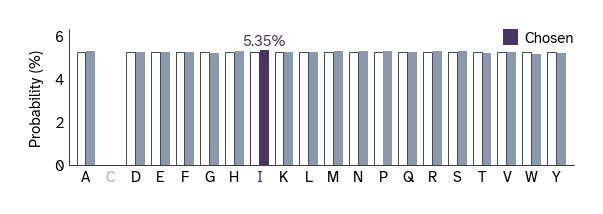

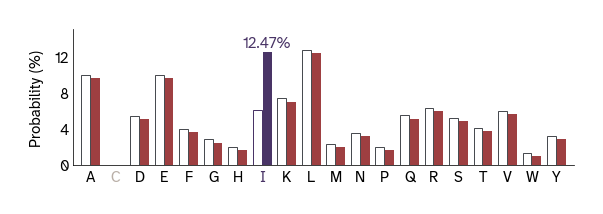

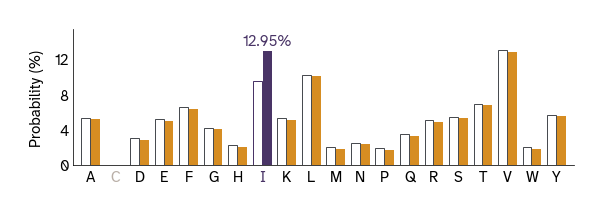

In [15]:
# | label: fig-initialization-priors
# | fig-cap: "Initializing one sequence position with isoleucine (I) as the most probable amino acid. Unfilled bars show initial probabilities; adjacent filled bars show probabilities after adjustment. Panel y-axis ranges differ. The uniform example uses an illustrative draw of small random score perturbations. Helix and sheet priors use the minimum boost at temperature 1 and a probability margin of 0.001. Cysteine is excluded."
# | fig-subcap:
# |   - "Uniform"
# |   - "Helix prior"
# |   - "Sheet prior"
# | layout-ncol: 1
# | code-fold: true
# | code-summary: "Compare three starting distributions with isoleucine as the chosen identity"

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

amino_acids = list("ACDEFGHIKLMNPQRSTVWY")
chosen_amino_acid = "I"
random_scores = 0.01 * np.random.default_rng(7).normal(size=20)
random_scores[amino_acids.index("C")] = -1e6
uniform_input = np.exp(random_scores - random_scores.max())
uniform_input /= uniform_input.sum()

example_priors = {"uniform": np.full(19, 1 / 19), **state_priors}
initialized_examples = {"uniform": pd.Series(uniform_input, index=amino_acids)}
for state, probabilities in state_priors.items():
    initialized = priors.matched_probabilities(
        probabilities, chosen_amino_acid, temperature=1
    )[0]
    initialized_examples[state] = pd.Series(initialized, index=priors.AA)

for state, probabilities in example_priors.items():
    figures.initialization_prior(
        pd.Series(probabilities, index=priors.AA),
        initialized_examples[state],
        state,
        chosen_amino_acid,
        legend=state == "uniform",
    )
    plt.show()

### Changing initial probabilities redirects early optimization

We ran 10 matched sets of uniform, helix-prior, and sheet-prior trajectories against PD-L1 IgV: 30 trajectories in total, each with a 120-residue binder. Each set shared its initial discrete sequence and exact atom features. All three conditions used the minimum-boost rule with a probability margin of 0.001, including the uniform control. The random perturbations illustrated in @fig-initialization-priors-1 describe the default workflow; this controlled comparison used the same initialization rule for every prior.

We used temperature $T=1$ and the original objective without a helicity penalty. We ran the first 40 updates on the ordinary 150-update annealing schedule. For composition measurements, we folded each saved soft sequence separately with 50 structure-solver steps and one recycle. The recorded states precede each update, so the last sampled state has completed 39 updates.

In [4]:
# | code-fold: true
# | code-summary: "Measure each prior's saved structures and flag unreliable coordinate readouts"

PRIOR_ARMS = list(targets.SHORT_TRAJECTORY_ARMS.values())
prior_trajectories = {}
for arm in PRIOR_ARMS:
    prior_trajectories[arm] = composition.measure_steps(targets.INITIALIZATION_TARGET, arm)

prior_trace = pd.concat(prior_trajectories.values(), ignore_index=True)
loss_trace.validate_matching(prior_trace)

# Coordinate quality affects DSSP fractions, not the independent optimizer metrics.
composition_columns = [f"{state} (fraction 0-1)" for state in ("helix", "sheet", "coil")]
invalid_readouts = ~prior_trace["geometry pass (bool)"]
prior_trace.loc[invalid_readouts, composition_columns] = float("nan")

In [5]:
# | code-fold: true
# | code-summary: "Average matched trajectories and compare sheet content at the last sampled state"

prior_metrics = [*composition_columns, "helix_mean (0-1)", "sequence entropy (bits)"]
prior_means = prior_trace.groupby(["arm", "step (index)"])[prior_metrics].mean()

last_prior_step = prior_trace["step (index)"].max()
last_prior_states = prior_trace[prior_trace["step (index)"] == last_prior_step]
last_prior_means = last_prior_states.groupby("arm")[prior_metrics].mean()

sheet_by_start = last_prior_states.pivot(
    index="seed", columns="arm", values="sheet (fraction 0-1)"
)
sheet_gain = (
    sheet_by_start[targets.SHORT_TRAJECTORY_ARMS["sheet"]]
    - sheet_by_start[targets.SHORT_TRAJECTORY_ARMS["uniform"]]
)

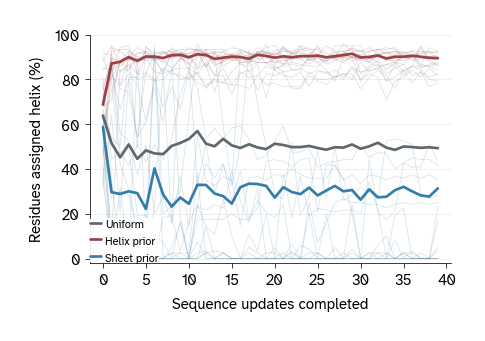

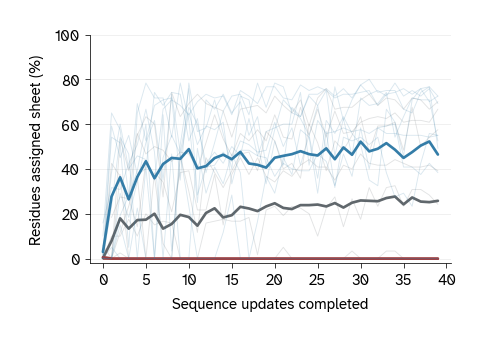

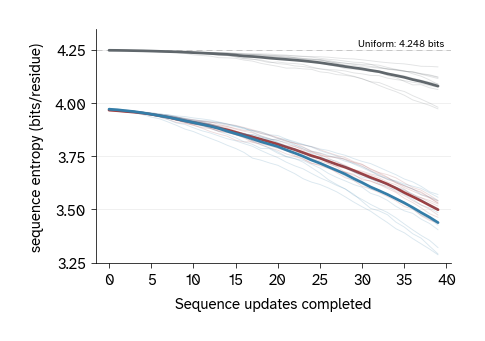

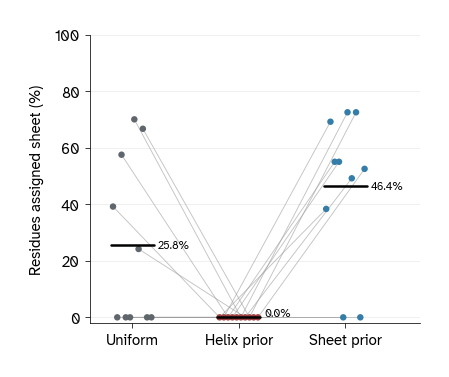

In [14]:
# | label: fig-initialization-trajectories
# | fig-cap: "Initialization changes early composition under the original objective. Ten matched starts per prior, PD-L1 IgV, temperature 1, and no helicity penalty. In panels a–c, thin lines show individual trajectories and thick lines show means. Helix and sheet fractions come from separate coordinate readouts; entropy comes from the optimizer's soft sequence. The dashed line marks uniform entropy over 19 allowed amino acids. Composition omits two flagged uniform readouts at states 0 and 1; entropy retains all ten starts. In panel d, connected points share initial sequences and atom features, and black bars show means. These are early states, before final confidence evaluation."
# | fig-subcap:
# |   - "Helix content"
# |   - "Sheet content"
# |   - "Soft-sequence entropy"
# |   - "Sheet content after 39 updates"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Plot composition, entropy, and matched sheet outcomes"

from matplotlib import pyplot as plt

for metric in ("helix", "sheet", "entropy"):
    figures.prior_trajectory_panel(
        prior_trace, prior_means, PRIOR_ARMS, metric, legend=metric == "helix"
    )
    plt.show()

figures.matched_composition_panel(last_prior_states, last_prior_means, PRIOR_ARMS, "sheet")
plt.show()

The starting probabilities redirected optimization within the first update (@fig-initialization-trajectories). After one update, helix-prior designs averaged 87% helix, whereas sheet-prior designs averaged 30% helix and 28% sheet. Their sequence entropies had barely changed from initialization. The helix and sheet priors also began with almost identical entropy, 3.967 and 3.971 bits per position. Their different responses point to which amino acids the priors favor as an influence on composition.

At the last sampled state, the sheet prior averaged 46.4% sheet, compared with 25.8% for the uniform control. Sheet content increased in six of the ten matched starts, decreased in two, and was unchanged in two (@fig-initialization-trajectories-4). The helix prior increased helicity in all ten starts, reaching a mean of 89.4% helix compared with 49.3% for uniform. Initialization can therefore shift early composition without changing the objective. Whether that shift survives full optimization and preserves confidence remains the next test.

## Takeaways

Adding a local distance penalty changes the predicted secondary-structure composition of ESMFold2 binder designs across five targets. Despite lower average confidence, steering increases the number of candidates meeting a sheet-content and confidence screen. Weight 2.0 gives the largest pooled count, while the most productive weight varies by target.

Changing the starting probabilities also redirects early optimization without a helicity penalty. In matched PD-L1 runs, the sheet prior raises mean sheet content relative to a uniform control, while the helix prior increases helicity. Full optimization and confidence evaluation are still needed to establish whether initialization produces useful final candidates.

### What the experiments establish

An added objective can redirect the output of a pretrained binder-design workflow. Across five targets, increasing the helicity penalty shifts predicted structures toward sheet and loop, with lower confidence scores. Under the selected sheet and confidence criteria, weight 2.0 yields 29 candidates compared with 15 without steering (@tbl-sheet-screen). The per-target counts show why the choice of weight should also reflect the target.

Across five targets, helicity diverges under different steering weights while sequence entropy remains near its maximum. The matched initialization experiment shows that the starting amino-acid probabilities can redirect early composition even with the original objective and identical initial discrete sequences and atom features. The helix and sheet priors produce different trajectories despite similar starting entropy (@fig-initialization-trajectories). Additional experiments on when loss steering must act are reported in @sec-steering-timing.

Secondary-structure composition is one of many properties a design campaign might seek to control. Loss steering shows how changing an objective can customize ESMFold2's design procedure after training. Whether similar interventions can control other properties remains to be tested. The experimental usefulness and fold diversity of the resulting candidates remain open questions.

### The composition proxy leaves important properties unconstrained

A short-distance penalty can remove helices without specifying a complete alternative fold. It does not reward strand pairing, sheet closure, packing, or a particular binding interface. An optimizer can lower the penalty by producing extended or irregular structure, which is consistent with the increase in loop as well as sheet.

Secondary-structure fractions therefore need to be paired with structural inspection. A β-rich structure may be an open sheet with exposed edges, a compact sheet-containing fold, or a poorly packed arrangement. The present composition measurements do not quantify those alternatives, so they cannot support a claim of increased fold diversity or improved developability.

### The biological meaning of lower confidence remains unresolved

Loss steering produces more β-rich candidates with lower average confidence than the unsteered baseline. These score changes leave the central biological question unresolved. The scores may correctly identify structures that fold or bind poorly. Alternatively, the model may assign lower confidence to viable β-rich designs because they fall outside the structural compositions it most readily generates.

The strong helical preference of the unsteered workflow makes this possibility worth investigating. It establishes a bias in the generated composition distribution, but does not establish whether confidence is miscalibrated: a preference during design and an inaccurate assessment of a finished design are different observations. The practical consequence is substantial. If lower scores reflect weaker binders, steering carries a biological cost; if they underestimate viable β-rich candidates, confidence filtering could discard useful designs.

Experimental evaluation of the steered candidates is needed to determine what these score changes mean for binder design.

## Next steps

The initialization results establish an early effect. We next need full 150-update campaigns to learn whether the sheet enrichment persists and whether the resulting designs retain confidence. These short trajectories do not yet answer whether initialization can avoid the confidence cost observed with loss steering.

Our main next step is to test whether the β-rich candidates produced by loss steering are viable in the laboratory. We plan to evaluate whether these sequences yield folded proteins that bind their intended targets. This will establish whether expanding the predicted composition distribution also expands the pool of useful binders.

Those results will also help interpret the lower computational confidence of steered designs. The central question is whether the scores reflect a real loss of candidate quality, underestimate successful designs with different structural compositions, or capture some combination of the two.

## Appendix: Early steering has a lasting effect {#sec-steering-timing}

The trajectories show an early separation between steered and unsteered runs (@fig-trace). This raises two questions: can a penalty introduced later still redirect composition, and can early steering be withdrawn while preserving that change?

We tested these questions on PD-L1 with two parameter scans. For the *onset* scan, we varied the optimization step at which the helicity penalty was first applied, then kept it active for the rest of the run. For the *withdrawal* scan, we applied the penalty from the start and varied the step at which it was removed. Both scans used weight 2.0, which produced a strong composition response in @fig-trace. Each condition contains 30 designs, with 150 optimization steps per design (@fig-schedule).

:::{.callout-note title="Comparing steering schedules"}

Individual designs are not seed-reproducible in this workflow. These campaigns therefore compare outcome distributions under different schedules, rather than tracking the same design with and without a change in timing.

:::

In [18]:
# | code-fold: true
# | code-summary: "Measure onset and withdrawal campaigns, reusing the shared endpoints"

SCAN_TARGET = "pdl1_igv"
scans = {"onset": targets.ONSET_SCAN, "withdrawal": targets.RELEASE_SCAN}
schedule_arms = set(scans["onset"].values()) | set(scans["withdrawal"].values())
for arm in sorted(schedule_arms):
    key = (SCAN_TARGET, arm)
    if key not in campaign_composition:
        campaign_composition[key] = composition.measure_campaign(*key)
        campaign_traces[key] = loss_trace.load_campaign(*key)

schedule_designs, schedule_medians = {}, {}
for name, scan in scans.items():
    schedule_designs[name] = pd.concat(
        [campaign_composition[SCAN_TARGET, arm] for arm in scan.values()], ignore_index=True
    )
    scan_trace = pd.concat([campaign_traces[SCAN_TARGET, arm] for arm in scan.values()])
    schedule_medians[name] = (
        scan_trace.groupby(["arm", "step (index)"])[["helix_mean (0-1)"]].median().reset_index()
    )

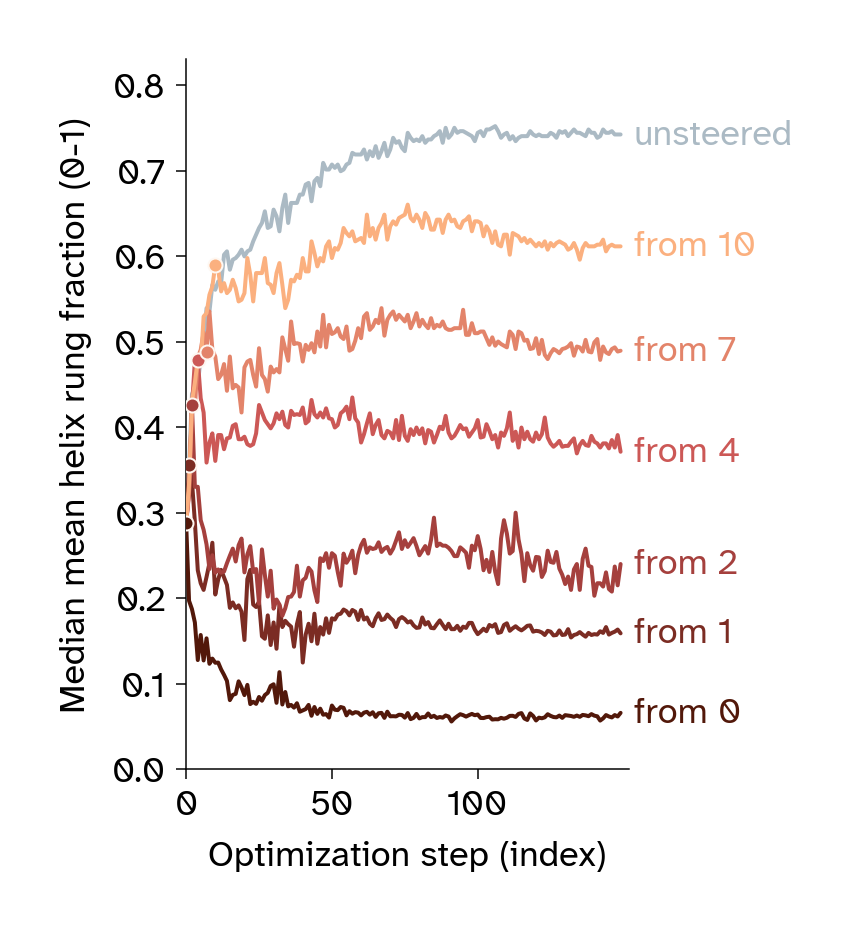

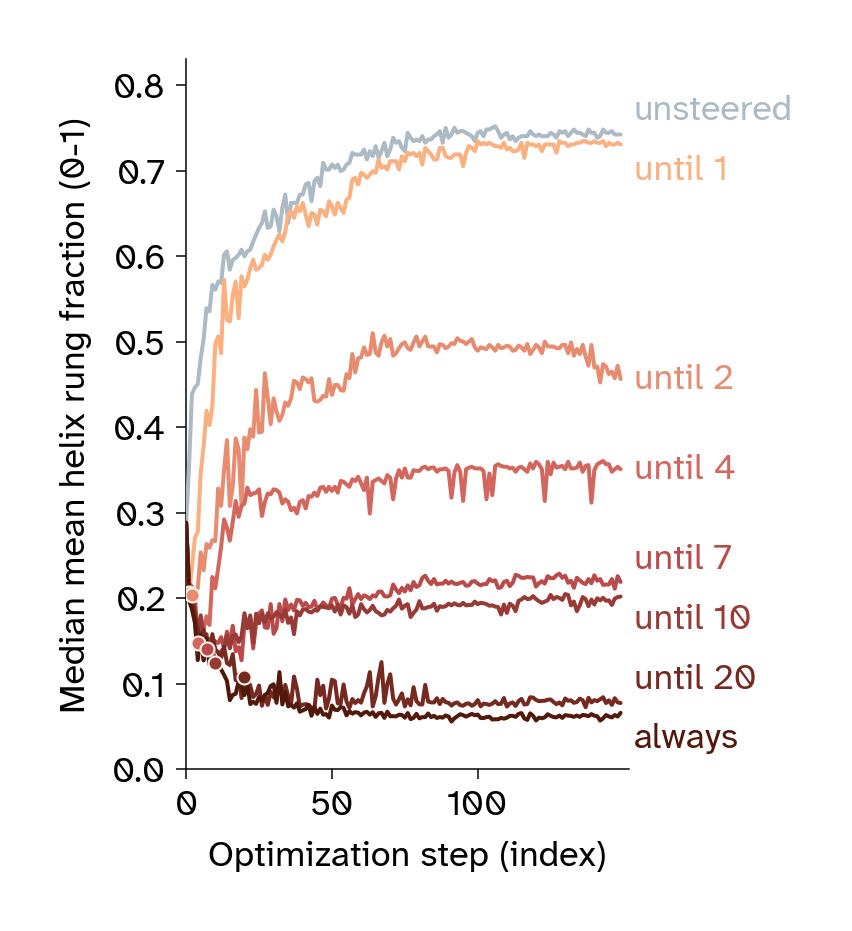

In [19]:
# | label: fig-schedule
# | fig-cap: "Median distogram helicity during PD-L1 optimization with delayed or withdrawn steering (weight 2.0; 30 designs per condition; 150 steps). Labels mark when the penalty begins ('from') or ends ('until'); dots mark switching steps. The unsteered and continuously steered campaigns are shared controls. These traces show the optimization proxy; final sheet fractions in the text are measured separately with PyDSSP."
# | fig-subcap:
# |   - "Delaying the start of steering"
# |   - "Stopping steering early"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Compare helicity trajectories under delayed and withdrawn steering"

drawn_steps = {
    "onset": (targets.SGD_STEPS, 0, 1, 2, 4, 7, 10),
    "withdrawal": (0, 1, 2, 4, 7, 10, 20, targets.SGD_STEPS),
}
for panel in figures.schedule_trace_panels(schedule_medians, scans, drawn_steps):
    display(panel)
    plt.close(panel)

In [20]:
# | code-fold: true
# | code-summary: "Calculate final sheet fractions separately from the optimization proxy"
# | output: false

schedule_sheet_medians = {}
for name, scan in scans.items():
    median_sheet = schedule_designs[name].groupby("arm")["sheet (fraction 0-1)"].median()
    schedule_sheet_medians[name] = pd.Series(
        {step: median_sheet[arm] for step, arm in scan.items()}, name="Median sheet fraction"
    )

Delaying steering until step 4 reduced median final sheet from 59% to less than 1%. Yet steering for only the first 20 steps left 55% median sheet after the remaining 130 steps without the penalty. Early steering therefore has a lasting effect on final composition.